# Rest, travel and time zones vs Elo residual

Charts for the rest and travel analysis. Input: `single_game_with_elo_corrected.csv` (made by `elo_from_23_corrected.ipynb`).

The outcome throughout is **`ELO_RESIDUAL`** = actual home margin − Elo-expected home margin. Positive means the home team did better than Elo expected. Team strength is already taken out, so what's left is what rest and travel might explain.

Each chart is also saved to `figures/`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

games = pd.read_csv("single_game_with_elo_corrected.csv")
os.makedirs("figures", exist_ok=True)

# Shared style
BG, INK, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#ebeae6", "#c9c8c3"
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#9a9993"
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG, "figure.dpi": 110})


def style(ax, title=None, xlabel=None, ylabel=None):
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=MUTED)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    if title:
        ax.set_title(title, loc="left", fontsize=12, color=INK)
    if xlabel:
        ax.set_xlabel(xlabel, color=MUTED)
    if ylabel:
        ax.set_ylabel(ylabel, color=MUTED)


def group_means(df, key):
    """Average residual, standard error and count for each value of key."""
    return df.groupby(key, observed=False)["ELO_RESIDUAL"].agg(["mean", "sem", "count"])


def plot_means(ax, g, colors=BLUE):
    """Dots with 95% confidence intervals, labeled with the average."""
    x = np.arange(len(g))
    colors = colors if isinstance(colors, list) else [colors] * len(g)
    for i, (m, se) in enumerate(zip(g["mean"], g["sem"])):
        ax.errorbar(i, m, yerr=1.96 * se, fmt="o", color=colors[i], ms=8, capsize=5, lw=2, zorder=5)
        ax.annotate(f"{m:+.1f}", (i, m), xytext=(10, -3), textcoords="offset points", fontsize=9.5, color=INK)
    ax.set_xticks(x)
    ax.set_xlim(-0.4, len(g) - 0.4)


print(games.shape)

(3680, 20)


## 1. Main result: rest and travel in one model

One regression on the Elo residual with both teams' back-to-back flags and travel distances. Every row is shown from the point of view of the tired or traveling team, so **negative always means it hurt that team**. The away rows have their sign flipped for this, because the residual is from the home team's side.

47 season openers are left out because rest days are undefined for a team's first game.

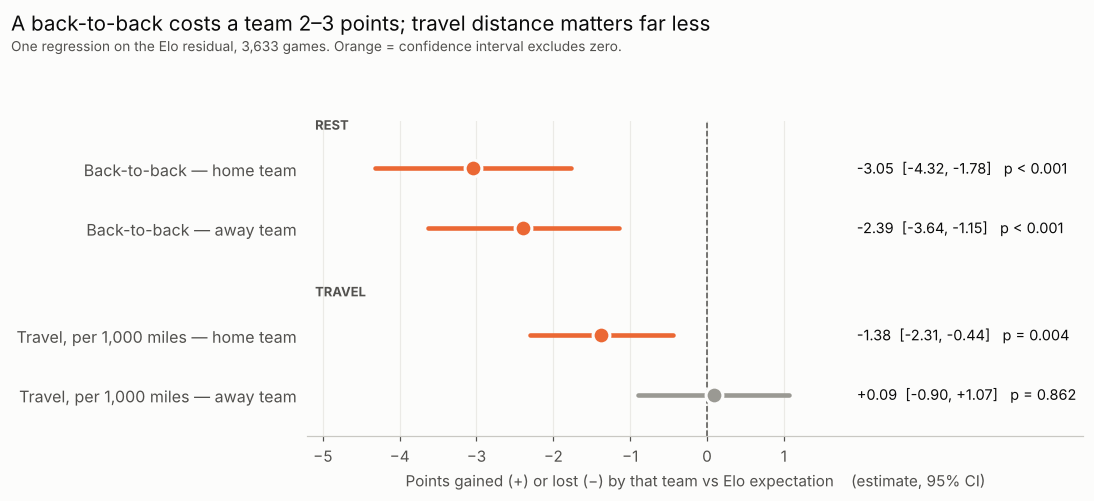

,effect,estimate,ci_low,ci_high,p
0,Back-to-back — home team,-3.049,-4.323,-1.776,0.000
1,Back-to-back — away team,-2.391,-3.636,-1.146,0.000
2,"Travel, per 1,000 miles — home team",-1.376,-2.309,-0.442,0.004
3,"Travel, per 1,000 miles — away team",0.088,-0.897,1.072,0.862


In [2]:
df = games.dropna(subset=["REST_DAYS_home", "REST_DAYS_away"]).copy()
df["b2b_home"] = (df["REST_DAYS_home"] == 0).astype(int)
df["b2b_away"] = (df["REST_DAYS_away"] == 0).astype(int)
df["travel_home"] = df["TRAVEL_DISTANCE_MILES_home"] / 1000
df["travel_away"] = df["TRAVEL_DISTANCE_MILES_away"] / 1000

model = smf.ols("ELO_RESIDUAL ~ b2b_home + b2b_away + travel_home + travel_away", df).fit(cov_type="HC1")
ci = model.conf_int()

rows = [  # (label, term, sign to make it "effect on that team")
    ("Back-to-back — home team", "b2b_home", 1),
    ("Back-to-back — away team", "b2b_away", -1),
    ("Travel, per 1,000 miles — home team", "travel_home", 1),
    ("Travel, per 1,000 miles — away team", "travel_away", -1),
]
effects = pd.DataFrame([
    {"effect": label,
     "estimate": sign * model.params[term],
     "ci_low": min(sign * ci.loc[term, 0], sign * ci.loc[term, 1]),
     "ci_high": max(sign * ci.loc[term, 0], sign * ci.loc[term, 1]),
     "p": model.pvalues[term]}
    for label, term, sign in rows
])

fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.array([4.2, 3.2, 1.4, 0.4])
for yi, r in zip(y, effects.itertuples()):
    color = GRAY if r.ci_low < 0 < r.ci_high else ORANGE
    ax.plot([r.ci_low, r.ci_high], [yi, yi], color=color, lw=3, solid_capstyle="round")
    ax.plot(r.estimate, yi, "o", color=color, ms=11, mec=BG, mew=2, zorder=5)
    p_text = "p < 0.001" if r.p < 0.001 else f"p = {r.p:.3f}"
    ax.text(1.95, yi, f"{r.estimate:+.2f}  [{r.ci_low:+.2f}, {r.ci_high:+.2f}]   {p_text}", va="center", fontsize=9.5, color=INK)
ax.axvline(0, color=MUTED, lw=1, ls="--")
ax.set_yticks(y)
ax.set_yticklabels(effects["effect"], fontsize=10.5, color=INK)
ax.set_xlim(-5.2, 4.9)
ax.set_ylim(-0.3, 5)
ax.set_xticks(range(-5, 2))
ax.text(-5.1, 4.85, "REST", fontsize=8.5, color=MUTED, weight="bold")
ax.text(-5.1, 2.05, "TRAVEL", fontsize=8.5, color=MUTED, weight="bold")
style(ax, xlabel="Points gained (+) or lost (−) by that team vs Elo expectation    (estimate, 95% CI)")
ax.spines["left"].set_visible(False)
ax.tick_params(left=False)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.grid(axis="y", visible=False)
fig.suptitle("A back-to-back costs a team 2–3 points; travel distance matters far less", x=0.01, ha="left", fontsize=13.5, color=INK)
fig.text(0.01, 0.90, f"One regression on the Elo residual, {int(model.nobs):,} games. Orange = confidence interval excludes zero.", fontsize=9, color=MUTED)
fig.tight_layout(rect=(0, 0, 1, 0.88))
fig.savefig("figures/rest_travel_effects.png", dpi=150)
plt.show()
effects.round(3)

## 2. Rest days

Average residual for each number of rest days, with 95% confidence intervals. Orange marks back-to-backs (0 days). On the right, a **higher** dot means the away team did **worse**.

Compare the dots with each other, not with zero. All the averages sit below zero because Elo's 100-point home-court bonus is a bit too large for these seasons.

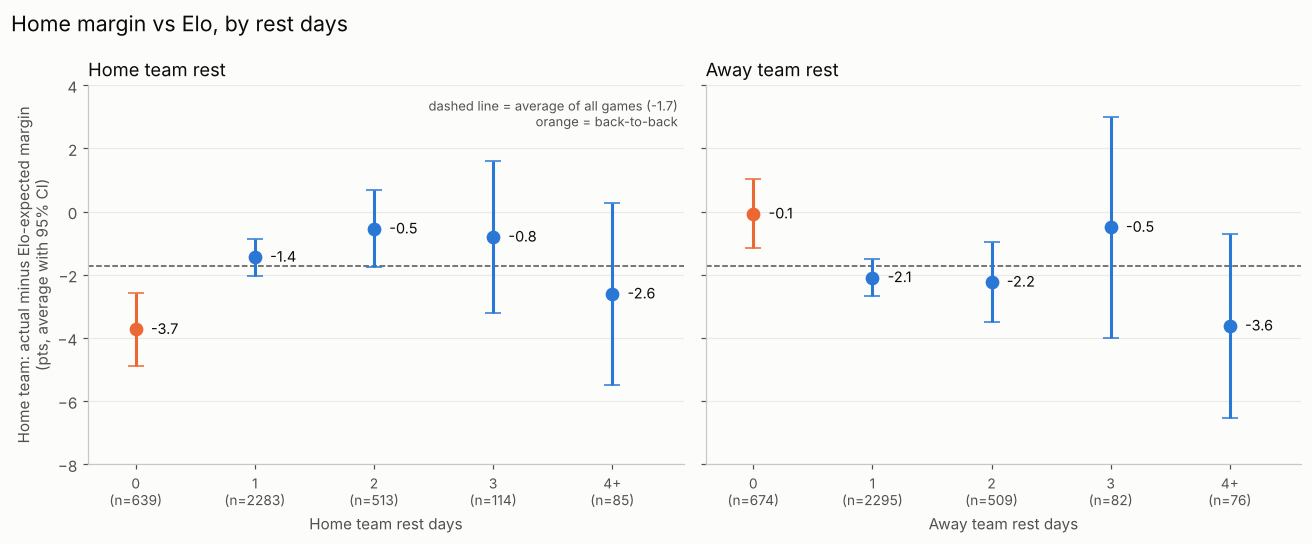

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
overall = games.dropna(subset=["REST_DAYS_home", "REST_DAYS_away"])["ELO_RESIDUAL"].mean()

for ax, side in zip(axes, ["home", "away"]):
    d = games.dropna(subset=[f"REST_DAYS_{side}"]).copy()
    d["rest"] = d[f"REST_DAYS_{side}"].clip(upper=4).astype(int)
    g = group_means(d, "rest")
    ax.axhline(overall, color=MUTED, lw=1, ls="--")
    plot_means(ax, g, colors=[ORANGE] + [BLUE] * (len(g) - 1))
    labels = ["0", "1", "2", "3", "4+"]
    ax.set_xticklabels([f"{l}\n(n={n})" for l, n in zip(labels, g["count"])], fontsize=9)
    style(ax, title=f"{side.capitalize()} team rest", xlabel=f"{side.capitalize()} team rest days")

axes[0].set_ylim(-8, 4)
axes[0].text(4.55, 3.6, f"dashed line = average of all games ({overall:+.1f})\norange = back-to-back", ha="right", va="top", fontsize=8.5, color=MUTED)
axes[0].set_ylabel("Home team: actual minus Elo-expected margin\n(pts, average with 95% CI)", color=MUTED)
fig.suptitle("Home margin vs Elo, by rest days", x=0.01, ha="left", fontsize=14, color=INK)
fig.tight_layout()
fig.savefig("figures/rest_binned.png", dpi=150)
plt.show()

## 3. Travel distance, grouped

The same idea for travel. For the home team, 0 miles means it was already home for its previous game.

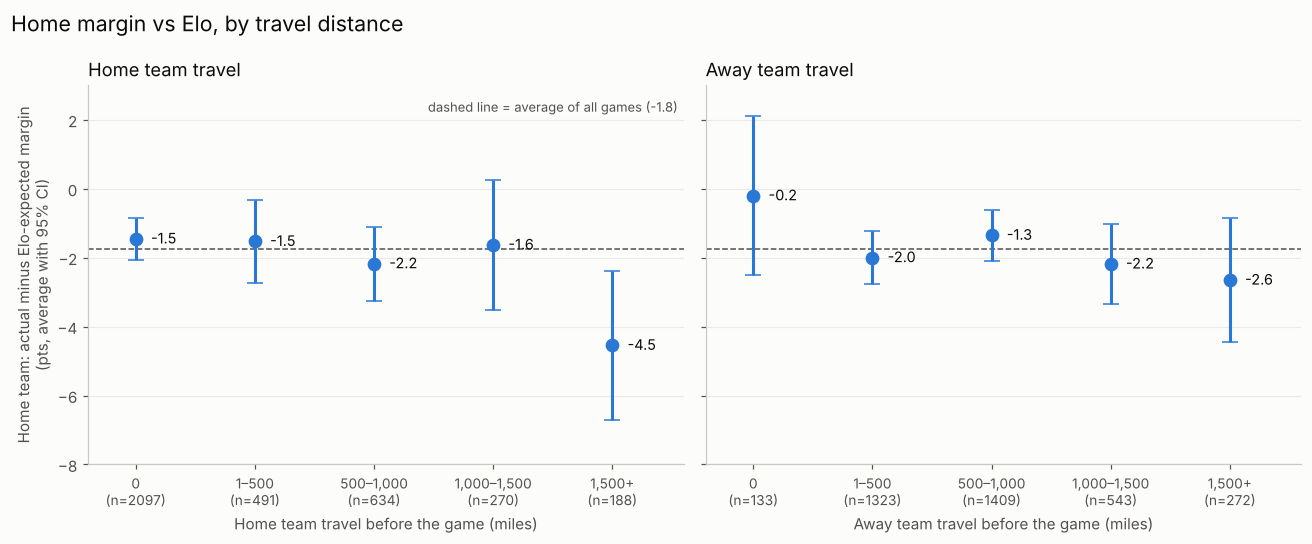

In [4]:
bins = [-1, 1, 500, 1000, 1500, 3000]
labels = ["0", "1–500", "500–1,000", "1,000–1,500", "1,500+"]
overall = games["ELO_RESIDUAL"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, side in zip(axes, ["home", "away"]):
    d = games.copy()
    d["travel_bin"] = pd.cut(d[f"TRAVEL_DISTANCE_MILES_{side}"], bins, labels=labels)
    g = group_means(d, "travel_bin")
    ax.axhline(overall, color=MUTED, lw=1, ls="--")
    plot_means(ax, g)
    ax.set_xticklabels([f"{l}\n(n={n})" for l, n in zip(labels, g["count"])], fontsize=9)
    style(ax, title=f"{side.capitalize()} team travel", xlabel=f"{side.capitalize()} team travel before the game (miles)")

axes[0].set_ylim(-8, 3)
axes[0].text(4.55, 2.6, f"dashed line = average of all games ({overall:+.1f})", ha="right", va="top", fontsize=8.5, color=MUTED)
axes[0].set_ylabel("Home team: actual minus Elo-expected margin\n(pts, average with 95% CI)", color=MUTED)
fig.suptitle("Home margin vs Elo, by travel distance", x=0.01, ha="left", fontsize=14, color=INK)
fig.tight_layout()
fig.savefig("figures/travel_binned.png", dpi=150)
plt.show()

## 4. Travel distance, every game

Each dot is one game, with a straight-line fit. Game-to-game noise (±40 points) is far larger than any travel effect, which is why the grouped charts above are easier to read.

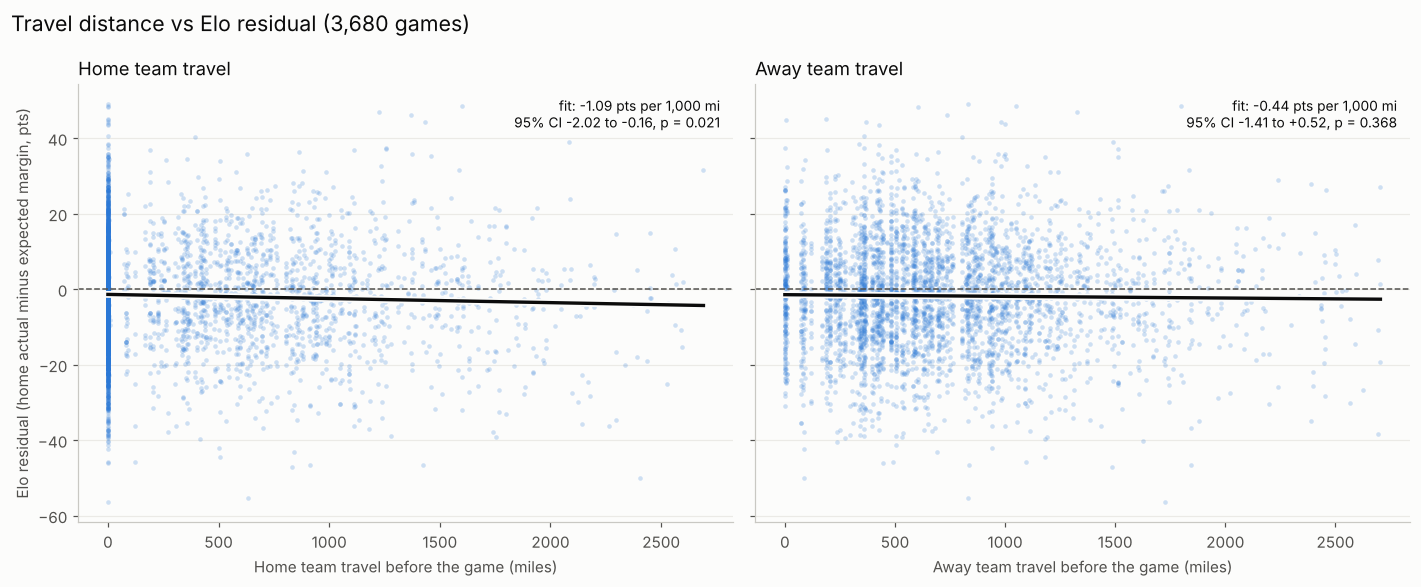

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), sharey=True)
for ax, side in zip(axes, ["home", "away"]):
    col = f"TRAVEL_DISTANCE_MILES_{side}"
    ax.scatter(games[col], games["ELO_RESIDUAL"], s=9, color=BLUE, alpha=0.22, lw=0)
    fit = smf.ols(f"ELO_RESIDUAL ~ I({col} / 1000)", games).fit(cov_type="HC1")
    term = fit.params.index[1]
    b, se, p = fit.params[term], fit.bse[term], fit.pvalues[term]
    xs = np.linspace(0, games[col].max(), 50)
    ys = fit.params.iloc[0] + b * xs / 1000
    ax.plot(xs, ys, color=BG, lw=4.5)
    ax.plot(xs, ys, color=INK, lw=2.2)
    ax.axhline(0, color=MUTED, lw=1, ls="--")
    ax.text(0.98, 0.97, f"fit: {b:+.2f} pts per 1,000 mi\n95% CI {b - 1.96 * se:+.2f} to {b + 1.96 * se:+.2f}, p = {p:.3f}",
            transform=ax.transAxes, ha="right", va="top", fontsize=9, color=INK)
    style(ax, title=f"{side.capitalize()} team travel", xlabel=f"{side.capitalize()} team travel before the game (miles)")

axes[0].set_ylabel("Elo residual (home actual minus expected margin, pts)", color=MUTED)
fig.suptitle(f"Travel distance vs Elo residual ({len(games):,} games)", x=0.01, ha="left", fontsize=14, color=INK)
fig.tight_layout()
fig.savefig("figures/travel_vs_residual.png", dpi=150)
plt.show()

## 5. Time-zone change

`TZ_CHANGE` is the hours the team's clock moved since its previous game. Positive means it traveled east. Left out: 47 season openers (no previous game) and 4 games right after a European trip (shifts of 5–7 hours).

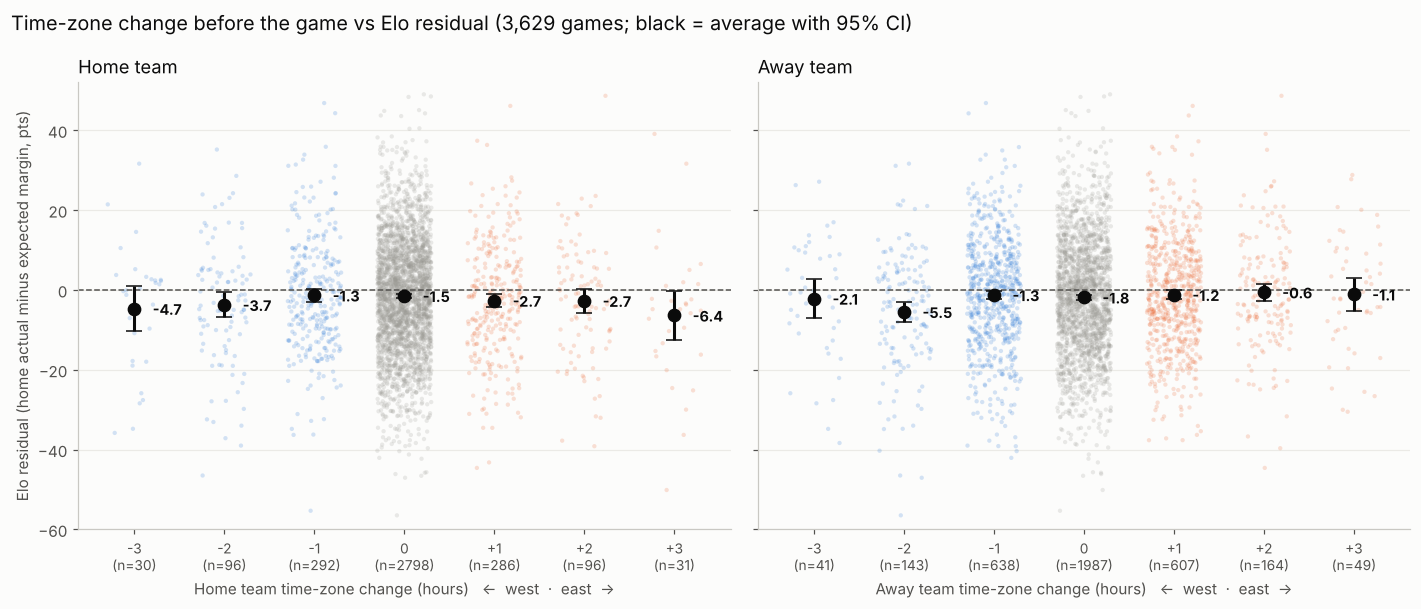

In [6]:
d = games.dropna(subset=["TZ_CHANGE_home", "TZ_CHANGE_away"])
d = d[(d["TZ_CHANGE_home"].abs() <= 3) & (d["TZ_CHANGE_away"].abs() <= 3)]
rng = np.random.default_rng(0)


def direction_color(hours):
    return BLUE if hours < 0 else ORANGE if hours > 0 else GRAY


fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), sharey=True)
for ax, side in zip(axes, ["home", "away"]):
    shift = d[f"TZ_CHANGE_{side}"].astype(int)
    ax.scatter(shift + rng.uniform(-0.3, 0.3, len(d)), d["ELO_RESIDUAL"], s=8,
               c=[direction_color(h) for h in shift], alpha=0.2, lw=0)
    g = d.groupby(shift)["ELO_RESIDUAL"].agg(["mean", "sem", "count"])
    for hours, r in g.iterrows():
        ax.errorbar(hours, r["mean"], yerr=1.96 * r["sem"], fmt="o", color=INK, ms=8, capsize=5, lw=2, zorder=5)
        ax.annotate(f"{r['mean']:+.1f}", (hours, r["mean"]), xytext=(12, -4), textcoords="offset points",
                    fontsize=9.5, color=INK, weight="bold")
    ax.axhline(0, color=MUTED, lw=1, ls="--")
    ax.set_xticks(g.index)
    ax.set_xticklabels([f"{h:+d}\n(n={n})" if h else f"0\n(n={n})" for h, n in zip(g.index, g["count"])], fontsize=9)
    style(ax, title=f"{side.capitalize()} team",
          xlabel=f"{side.capitalize()} team time-zone change (hours)   ←  west  ·  east  →")

axes[0].set_ylabel("Elo residual (home actual minus expected margin, pts)", color=MUTED)
axes[0].set_ylim(-60, 52)
fig.suptitle(f"Time-zone change before the game vs Elo residual ({len(d):,} games; black = average with 95% CI)",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout()
fig.savefig("figures/timezone_vs_residual.png", dpi=150)
plt.show()